# Notebook 15 — Đối chứng mean/CVaR trên p0_reference

Chạy **4 lượt mới**: mean/common, mean/alternative, CVaR/common, CVaR/alternative. Không cần đổi notebook 14 và không cần lấy kết quả choice làm baseline cho reference.

Giữ p=1, penalty (3,3), mixer X, max_abs, COBYLA tối đa 200 lần đánh giá/lượt, alpha=0.1, 1.024 shots cuối/lượt. Hai objective đều tính từ statevector lý tưởng trên CPU. Mỗi cặp dùng cùng khởi tạo ban đầu, không warm start từ góc mean đã tối ưu.

Chạy tuần tự từ trên xuống trong kernel `nt409-khiem`. Hướng dẫn chi tiết: `docs/qaoa_reference_control.md`.

## Bước 1 — Kiểm tra kernel
Restart Kernel trước khi chạy. Đường dẫn Python phải thuộc môi trường Conda của bạn.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import sys, json, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil, scipy
from IPython.display import display
ROOT=Path.cwd().resolve()
if not (ROOT/"src/qubo.py").is_file(): ROOT=ROOT.parent
if not (ROOT/"src/qubo.py").is_file(): raise RuntimeError("Mở notebook từ repo nt409-task-placement.")
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.qubo import build_qubo
from src.qaoa_experiment import prepare_reference, experiment_environment, _MemoryMonitor
from src.convergence_diagnostics import run_exact_qaoa
from src import convergence_campaign as mean_campaign
from src import cvar_experiment as cvar_campaign
assert tuple(map(int,scipy.__version__.split('.')[:2])) >= (1,16)
print("Python:",sys.executable)
print(json.dumps(experiment_environment()["runtime"],indent=2))

Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
{
  "python_version": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy_version": "2.5.3",
  "scipy_version": "1.18.1",
  "qiskit_version": "2.5.2",
  "qiskit_optimization_version": "0.7.0",
  "qiskit_aer_version": "0.17.2"
}


## Bước 2 — Cấu hình cố định
Lần đầu giữ `RESUME_DIR=None`. Nếu bị gián đoạn, thay bằng đường dẫn `RESUME_DIR` được in ở bước 3 rồi Restart Kernel và chạy lại từ đầu. Đừng đổi các tham số khác khi resume.

`maxiter=200` là giới hạn số lần đánh giá hàm, không yêu cầu mọi lượt chạy đủ 200. Seed cuối 100060 tách khỏi seed huấn luyện 60. Cùng seed giữa các nhánh không tạo thành nhiều lần lặp thống kê độc lập.

In [2]:
RESUME_DIR=None
ALPHA=0.1
SEED=60
STARTS={"common":[0.3,1.0],"alternative":[0.8,1.2]}
BASE_CONFIG=dict(shots=1024,evaluation_shots=1024,maxiter=200,max_seconds=600.,
    max_qubits=23,aer_threads=4,aer_memory_mb=2048,min_available_gib=2.,
    hamiltonian_scaling="max_abs",cobyla_rhobeg=1.,cobyla_tol=1e-4)
instance=json.loads((ROOT/"data/instances/p0_reference.json").read_text(encoding="utf-8"))
bundle=build_qubo(instance,assignment_penalty=3,capacity_penalty=3)
reference=prepare_reference(bundle)
assert instance["instance_id"]=="p0_reference" and bundle["qubo"].get_num_vars()==23
assert reference["minimum_energy"]==2
print("p0_reference | 23 qubit | E_min=2 | 4 lượt mới | alpha=0.1")

p0_reference | 23 qubit | E_min=2 | 4 lượt mới | alpha=0.1


## Bước 3 — Tạo hoặc mở lại thí nghiệm
Hai manifest lưu hai nhóm mean và CVaR. Nhóm CVaR liên kết đúng campaign mean vừa tạo, cùng instance, môi trường và cấu hình. Lưu lại dòng `RESUME_DIR` ngay khi bước này hoàn tất.

Resume xác minh cả report đã lưu và cấu hình. Nếu báo mã nguồn/runtime khác, dừng và gửi lỗi; không sửa manifest để ép chạy tiếp.

In [3]:
mean_design=mean_campaign.make_design(instance,bundle,[SEED],BASE_CONFIG,STARTS,objective_modes=("exact",))
mean_design["study"].update(stage="reference_mean_cvar_control",quality_metric="ideal_optimal_placement_probability")
if RESUME_DIR is None:
    stamp=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    RESULT_DIR=ROOT/"data/reference_results/phase4g_reference_control"/f"reference_{stamp}"
    RESULT_DIR.mkdir(parents=True,exist_ok=False)
else:
    RESULT_DIR=(ROOT/RESUME_DIR).resolve()
    if not RESULT_DIR.is_relative_to(ROOT) or not RESULT_DIR.is_dir():
        raise ValueError("RESUME_DIR phải là thư mục thí nghiệm đã có trong repo.")
MEAN_PATH=RESULT_DIR/"mean_manifest.json"
CVAR_PATH=RESULT_DIR/"cvar_manifest.json"
if MEAN_PATH.exists():
    mean=json.loads(MEAN_PATH.read_text(encoding="utf-8"))
else:
    if CVAR_PATH.exists():raise ValueError("Thiếu manifest mean đã liên kết với CVaR.")
    mean=mean_campaign.new_campaign(mean_design)
    mean_campaign.save_campaign(MEAN_PATH,mean)
mean_campaign.verify_campaign(ROOT,mean,mean_design,bundle,reference)
baseline_identity=dict(instance_id=instance["instance_id"],mean_campaign_id=mean["campaign_id"],
    mean_design_hash=mean["design_hash"],mean_manifest=MEAN_PATH.relative_to(ROOT).as_posix())
cvar_design=cvar_campaign.make_design(instance,bundle,BASE_CONFIG,STARTS,SEED,ALPHA,baseline_identity)
if CVAR_PATH.exists():
    cvar=json.loads(CVAR_PATH.read_text(encoding="utf-8"))
else:
    cvar=cvar_campaign.new_campaign(cvar_design)
    cvar_campaign.save_campaign(CVAR_PATH,cvar)

def verify_study():
    mr=mean_campaign.verify_campaign(ROOT,mean,mean_design,bundle,reference)
    cr=cvar_campaign.verify_campaign(ROOT,cvar,cvar_design,bundle,reference)
    mt={t["initial_point_id"]:t for t in mean["planned_runs"]}
    ct={t["initial_point_id"]:t for t in cvar["planned_runs"]}
    if set(mt)!=set(ct) or len(mt)!=2:raise ValueError("Cần đúng hai cặp khởi tạo.")
    for start in mt:
        if mt[start]["config"]!=ct[start]["config"]:raise ValueError("Cấu hình mean/CVaR không khớp.")
    return mr,cr

mean_rows,cvar_rows=verify_study()
print("RESUME_DIR =",repr(RESULT_DIR.relative_to(ROOT).as_posix()))
print("Đã hoàn tất:",len(mean_rows)+len(cvar_rows),"/ 4")
display(pd.DataFrame([dict(arm=t["arm_id"],start=t["config"]["initial_point"],
    maxiter=t["config"]["maxiter"],final_shots=t["config"]["evaluation_shots"],
    final_seed=t["config"]["evaluation_seed"]) for group in (mean,cvar) for t in group["planned_runs"]]))

RESUME_DIR = 'data/reference_results/phase4g_reference_control/reference_20261010T022352464276Z'
Đã hoàn tất: 0 / 4


,arm,start,maxiter,final_shots,final_seed
0,exact_common,"[0.3, 1.0]",200,1024,100060
1,exact_alternative,"[0.8, 1.2]",200,1024,100060
2,cvar_common,"[0.3, 1.0]",200,1024,100060
3,cvar_alternative,"[0.8, 1.2]",200,1024,100060


## Bước 4 — Kiểm tra tài nguyên 23 qubit
Dùng một oracle chung và chạy tuần tự bốn lượt. Đo thời gian một lần chấm mean và CVaR tại góc đầu; ước lượng có hệ số dự phòng nhưng không phải cam kết thời gian. Nếu RAM khả dụng dưới 2 GiB hoặc ước lượng vượt giới hạn 600 giây/lượt, bước này dừng để bạn kiểm tra máy.

CVaR lấy 10% **khối lượng xác suất** có năng lượng thấp nhất, gồm phần xác suất tại ranh giới. Giá trị này khác năng lượng trung bình.

In [4]:
config=mean["planned_runs"][0]["config"]
if psutil.virtual_memory().available/2**30<BASE_CONFIG["min_available_gib"]:
    raise RuntimeError("RAM khả dụng dưới ngưỡng; đóng ứng dụng nặng rồi chạy lại.")
with _MemoryMonitor() as memory:
    oracle=cvar_campaign.ExactCVaROracle(bundle,config,reference)
    started=perf_counter();initial_mean=oracle.evaluate(STARTS["common"])
    mean_seconds=perf_counter()-started
    started=perf_counter();initial_cvar=oracle.cvar(STARTS["common"],ALPHA)
    cvar_seconds=perf_counter()-started
rough_mean=1.5*mean_seconds*(BASE_CONFIG["maxiter"]+3)
rough_cvar=1.5*cvar_seconds*(BASE_CONFIG["maxiter"]+3)
print(f"Ước lượng mean: {rough_mean:.1f}s/lượt; CVaR: {rough_cvar:.1f}s/lượt.")
print(f"Tổng 4 lượt khoảng {(2*rough_mean+2*rough_cvar)/60:.1f} phút, chưa gồm toàn bộ hậu xử lý.")
print("RSS sau chuẩn bị (MiB):",memory.as_dict()["process_peak_rss_mib"])
if max(rough_mean,rough_cvar)>BASE_CONFIG["max_seconds"]:
    raise RuntimeError("Ước lượng vượt time guard. Gửi output bước này để kiểm tra tài nguyên.")
assert np.isclose(oracle.cvar(STARTS["common"],1.),initial_mean["exact_mean_qubo_energy"],rtol=0,atol=1e-7)

Ước lượng mean: 156.9s/lượt; CVaR: 159.2s/lượt.
Tổng 4 lượt khoảng 10.5 phút, chưa gồm toàn bộ hậu xử lý.
RSS sau chuẩn bị (MiB): 655.83203125


## Bước 5 — Chạy bốn lượt và lưu sau mỗi lượt
Chạy mean/common → mean/alternative → CVaR/common → CVaR/alternative. Lượt đã lưu được bỏ qua khi resume. Lượt bị ngắt giữa chừng sẽ chạy lại từ đầu.

`success=False` do hết 200 lần đánh giá vẫn được lưu nếu report hoàn tất. Không loại lượt có 0 mẫu placement tối ưu. Nếu báo `time_budget_exceeded`, gửi output; chưa tăng ngân sách hoặc đổi tham số.

In [5]:
verify_study()
for group,path,kind in ((mean,MEAN_PATH,"mean"),(cvar,CVAR_PATH,"cvar")):
    completed={r["run_key"] for r in group["completed_runs"]}
    for trial in group["planned_runs"]:
        if trial["run_key"] in completed:continue
        print("\nĐang chạy",trial["arm_id"],flush=True)
        if kind=="mean":
            report=run_exact_qaoa(bundle,trial["config"],reference,oracle,progress=True)
        else:
            report=cvar_campaign.run_cvar_qaoa(bundle,trial["config"],ALPHA,reference,oracle,progress=True)
        if report["status"]!="completed":
            raise RuntimeError(f"Lượt {trial['arm_id']} chưa hoàn tất: {report['status']}. Giữ thư mục để resume.")
        if kind=="mean":
            saved=mean_campaign.record_trial(ROOT,group,trial,report,bundle,oracle)
        else:
            saved=cvar_campaign.record_trial(ROOT,group,trial,report,bundle,reference)
        mean_campaign.save_campaign(path,group)
        completed.add(trial["run_key"])
        print("Đã lưu:",saved.name,"|",report["optimizer_stop"],flush=True)
mean_rows,cvar_rows=verify_study()
print("Hoàn tất:",len(mean_rows)+len(cvar_rows),"/ 4")


Đang chạy exact_common
  exact evaluation 1: E=1538.157919, elapsed=0.0s
  exact evaluation 5: E=1145.770528, elapsed=2.2s
  exact evaluation 10: E=456.150264, elapsed=4.8s
  exact evaluation 15: E=370.533867, elapsed=7.4s
  exact evaluation 20: E=334.835108, elapsed=10.4s
  exact evaluation 25: E=201.719363, elapsed=14.8s
  exact evaluation 30: E=195.991160, elapsed=19.2s
  exact evaluation 35: E=177.648333, elapsed=22.1s
  exact evaluation 40: E=170.809262, elapsed=24.7s
  exact evaluation 45: E=171.008771, elapsed=27.3s
  exact evaluation 50: E=170.607749, elapsed=29.9s
  exact evaluation 55: E=170.550485, elapsed=32.5s
  exact evaluation 60: E=170.550659, elapsed=35.0s
  exact evaluation 65: E=170.547974, elapsed=37.4s
  exact evaluation 70: E=170.547862, elapsed=40.0s
Đã lưu: p0_reference_exact_common_seed60_20261010T022515165263Z.json | {'status': 0, 'success': True, 'message': 'Return from COBYLA because the trust region radius reaches its lower bound.', 'nfev': 72}

Đang chạy 

## Bước 6 — So sánh theo từng khởi tạo
`P_opt` là xác suất placement tối ưu lý tưởng, `P_feasible` là xác suất placement hợp lệ. `P_ground` còn yêu cầu slack đúng để đạt năng lượng QUBO nhỏ nhất. Giữ ba chỉ số riêng.

So CVaR tại cả góc mean và góc CVaR; tương tự với E_mean. `delta_P_opt_pp` là chênh lệch **điểm phần trăm**, không phải mức tăng tương đối. Số mẫu tối ưu cuối chỉ thuộc một batch 1.024 shots.

In [6]:
mean_rows,cvar_rows=verify_study()
assert len(mean_rows)==len(cvar_rows)==2
old_by_start={r["initial_point_id"]:r for r in mean_rows}
comparisons=[]
for row in cvar_rows:
    start=row["initial_point_id"];old=old_by_start[start]
    comparisons.append(dict(start=start,
        CVaR_at_mean=oracle.cvar(old["optimal_point"],ALPHA),CVaR_at_cvar=row["optimizer_objective_value"],
        E_mean_at_mean=old["exact_mean_qubo_energy"],E_mean_at_cvar=row["exact_mean_qubo_energy"],
        P_opt_mean_percent=100*old["exact_optimal_probability"],P_opt_cvar_percent=100*row["exact_optimal_probability"],
        delta_P_opt_pp=100*(row["exact_optimal_probability"]-old["exact_optimal_probability"]),
        P_feasible_mean_percent=100*old["exact_feasible_probability"],P_feasible_cvar_percent=100*row["exact_feasible_probability"],
        P_ground_mean_percent=100*old["exact_ground_probability"],P_ground_cvar_percent=100*row["exact_ground_probability"],
        optimal_shots_mean=round(old["optimal_placement_probability"]*old["evaluation_shots"]),
        optimal_shots_cvar=round(row["optimal_placement_probability"]*row["sampling"]["evaluation_shots"]),
        nfev_mean=old["cost_function_evals"],nfev_cvar=row["cost_function_evals"],
        success_mean=old["optimizer_success"],success_cvar=row["optimizer_stop"]["success"],
        stop_mean=old["optimizer_message"],stop_cvar=row["optimizer_stop"]["message"],
        seconds_mean=old["elapsed_seconds"],seconds_cvar=row["elapsed_seconds"],
        peak_rss_mib_mean=old["process_peak_rss_mib"],peak_rss_mib_cvar=row["process_peak_rss_mib"]))
comparison=pd.DataFrame(comparisons)
display(comparison.round(8))
print("Uniform P_opt (%):",100*reference["uniform_baseline"]["optimal_placement_probability"])
COMPARISON_PATH=RESULT_DIR/"reference_comparison.csv"
comparison.to_csv(COMPARISON_PATH,index=False,encoding="utf-8-sig")

,start,CVaR_at_mean,CVaR_at_cvar,E_mean_at_mean,E_mean_at_cvar,P_opt_mean_percent,P_opt_cvar_percent,delta_P_opt_pp,P_feasible_mean_percent,P_feasible_cvar_percent,...,nfev_mean,nfev_cvar,success_mean,success_cvar,stop_mean,stop_cvar,seconds_mean,seconds_cvar,peak_rss_mib_mean,peak_rss_mib_cvar
0,common,28.574853,27.386043,170.547790,196.641736,0.204637,0.136929,-0.067707,0.204637,0.136929,...,72,41,True,True,Return from COBYLA because the trust region ra...,Return from COBYLA because the trust region ra...,41.468545,21.242998,655.832031,655.832031
1,alternative,28.574780,27.386048,170.547791,196.867750,0.204631,0.136750,-0.067880,0.204631,0.136750,...,41,75,True,True,Return from COBYLA because the trust region ra...,Return from COBYLA because the trust region ra...,21.380716,43.352029,655.832031,655.832031


Uniform P_opt (%): 0.09765625


## Bước 7 — Quỹ đạo tối ưu
Hai cột dùng thang objective riêng. Không so trực tiếp chiều cao đường mean với đường CVaR. Đường ngang ở cột CVaR là CVaR chấm tại góc mean của cùng khởi tạo.

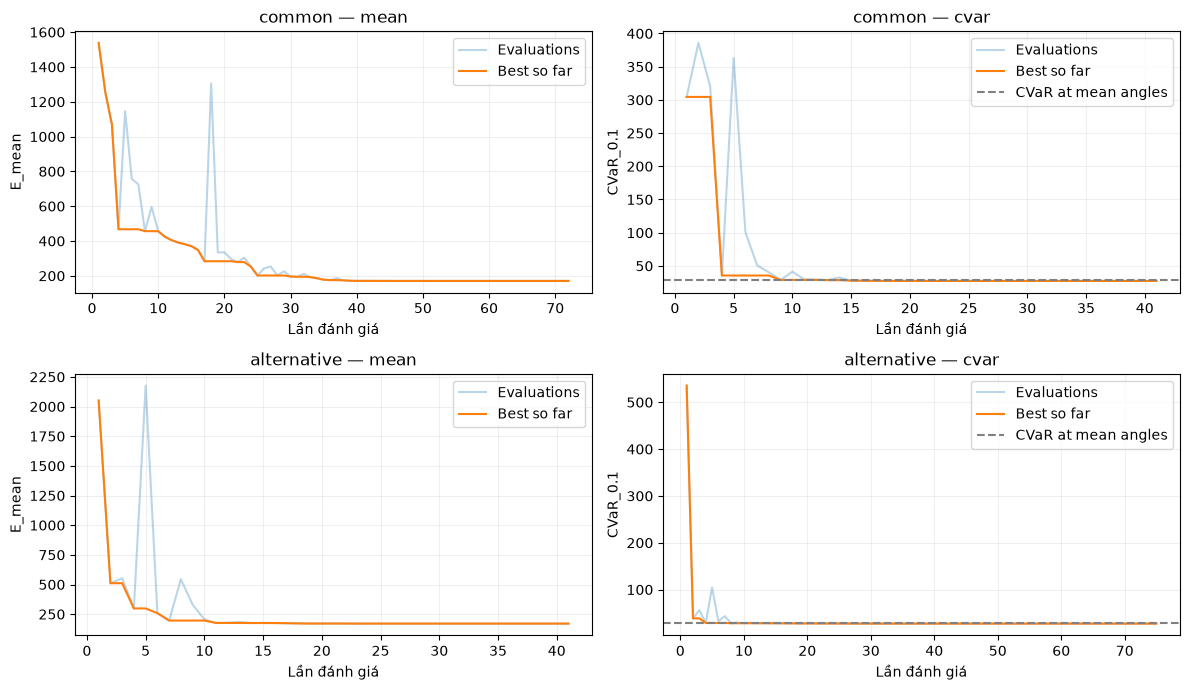

In [7]:
fig,axes=plt.subplots(2,2,figsize=(12,7))
for i,start in enumerate(STARTS):
    for j,(kind,rows) in enumerate((("mean",mean_rows),("cvar",cvar_rows))):
        row=next(r for r in rows if r["initial_point_id"]==start)
        report=json.loads((ROOT/row["report"]).read_text(encoding="utf-8"))
        key="estimated_qubo_energy" if kind=="mean" else "cvar_qubo_energy"
        values=np.array([h[key] for h in report["optimization_history"]])
        ax=axes[i,j];x=np.arange(1,len(values)+1)
        ax.plot(x,values,alpha=.3,label="Evaluations")
        ax.plot(x,np.minimum.accumulate(values),label="Best so far")
        if kind=="cvar":
            at_mean=next(c["CVaR_at_mean"] for c in comparisons if c["start"]==start)
            ax.axhline(at_mean,color="grey",linestyle="--",label="CVaR at mean angles")
        ax.set(title=f"{start} — {kind}",xlabel="Lần đánh giá",ylabel="E_mean" if kind=="mean" else "CVaR_0.1")
        ax.legend();ax.grid(alpha=.2)
fig.tight_layout()
PLOT_PATH=RESULT_DIR/"reference_traces.png"
fig.savefig(PLOT_PATH,dpi=150)
plt.show()

## Bước 8 — Xuất và gửi kết quả
Notebook tự kiểm tra đủ 4 report, đúng cấu hình và dữ liệu shots, rồi gom hai manifest, bốn report, CSV và đồ thị vào một ZIP. Các report gốc nằm trong thư mục kết quả của runner tương ứng và được đưa đầy đủ vào ZIP.

Sau khi thấy PASS, Save As thành `15_qaoa_reference_control_executed.ipynb`. Gửi notebook có output và ZIP được in bên dưới.

Đọc kết quả ở cả hai khởi tạo, kể cả khi CVaR không tăng P_opt. Chưa quét alpha, tăng p hoặc kéo dài lượt đạt cap trong đợt này. Reference giúp kiểm tra kết quả choice có xuất hiện ở instance khác không; hai instance chưa đủ để kết luận ưu thế tổng quát.

In [8]:
mean_rows,cvar_rows=verify_study()
assert len(mean_rows)==len(cvar_rows)==2
assert not mean["remaining_run_keys"] and not cvar["remaining_run_keys"]
for group in (mean,cvar):
    assert group["design"]["instance_id"]=="p0_reference"
    for t in group["planned_runs"]:
        assert t["config"]["maxiter"]==200 and t["config"]["reps"]==1
        assert t["config"]["evaluation_shots"]==1024
assert cvar["design"]["objective"]["alpha"]==0.1
paths=[MEAN_PATH,CVAR_PATH,COMPARISON_PATH,PLOT_PATH]+[ROOT/r["report"] for r in mean_rows+cvar_rows]
checksums={p.relative_to(ROOT).as_posix():hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
CHECKSUM_PATH=RESULT_DIR/"sha256.json"
CHECKSUM_PATH.write_text(json.dumps(checksums,indent=2)+"\n",encoding="utf-8")
EXPORT_PATH=RESULT_DIR/f"{RESULT_DIR.name}.zip"
with zipfile.ZipFile(EXPORT_PATH,"w",zipfile.ZIP_DEFLATED) as z:
    for p in paths+[CHECKSUM_PATH]:z.write(p,p.relative_to(ROOT).as_posix())
print("PASS — p0_reference: 4/4 completed, matched mean/CVaR controls verified.")
print("Gửi ZIP:",EXPORT_PATH.relative_to(ROOT).as_posix())
print("Save As: 15_qaoa_reference_control_executed.ipynb")

PASS — p0_reference: 4/4 completed, matched mean/CVaR controls verified.
Gửi ZIP: data/reference_results/phase4g_reference_control/reference_20261010T022352464276Z/reference_20261010T022352464276Z.zip
Save As: 15_qaoa_reference_control_executed.ipynb
